# EDA

In [2]:
# Imports Necesarios
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Cargar datasets 
ruta_clientes = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Clientes.csv'
ruta_categorias = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Categorias.csv'
ruta_detalles_de_pedidos = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Detalles de Pedidos.csv'
ruta_empleados = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Empleados.csv'
ruta_equipos = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Equipos.csv'
ruta_estaciones = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Estaciones.csv'
ruta_mantenimientos = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Mantenimientos.csv'
ruta_pedidos = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Pedidos.csv'
ruta_productos = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Productos.csv'
ruta_proveedores = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Proveedores.csv'


### Clientes

In [80]:
df_clientes = pd.read_csv(ruta_clientes, sep=';')

In [ ]:
# VISTA GENERAL
print(f"Dimensiones: {df_clientes.shape}")
df_clientes.head()

Dimensiones: (91, 11)


,Id. de cliente,Nombre de compañía,Nombre del contacto,Cargo del contacto,Dirección,Ciudad,Región,Código postal,País,Teléfono,Fax
0,PEBER,Petrolera Berlín,Maria Anders,Gerente de Estación de Servicio,Obere Str. 57,Berlín,NaN,12209,Alemania,030-0074321,030-0076545
1,DICOM,Distribuidora de Combustibles México D.F.,Ana Trujillo,Jefe de Operaciones,Avda. de la Constitución 2222,México D.F.,NaN,05021,México,(5) 555-4729,(5) 555-3745
2,ESSER,Estación de Servicio México D.F.,Antonio Moreno,Supervisor de Planta,Mataderos 2312,México D.F.,NaN,05023,México,(5) 555-3932,NaN
3,GALON,GasNorte Londres,Thomas Hardy,Coordinador de Logística,120 Hanover Sq.,Londres,NaN,WA1 1DP,Reino Unido,(71) 555-7788,(71) 555-6750
4,TECOM,Terminal de Combustibles Luleå,Christina Berglund,Gerente de Compras,Berguvsvägen 8,Luleå,NaN,S-958 22,Suecia,0921-12 34 65,0921-12 34 67


In [ ]:
# ESTRUCTURA Y TIPOS DE DATOS
df_clientes.info()
print(df_clientes.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91 entries, 0 to 90
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Id. de cliente       91 non-null     object
 1   Nombre de compañía   91 non-null     object
 2   Nombre del contacto  91 non-null     object
 3   Cargo del contacto   91 non-null     object
 4   Dirección            91 non-null     object
 5   Ciudad               91 non-null     object
 6   Región               31 non-null     object
 7   Código postal        90 non-null     object
 8   País                 91 non-null     object
 9   Teléfono             91 non-null     object
 10  Fax                  69 non-null     object
dtypes: object(11)
memory usage: 7.9+ KB
object    11
Name: count, dtype: int64


In [ ]:
# VALORES NULOS
nulos = df_clientes.isnull().sum()
pct_nulos = (nulos / len(df_clientes)) * 100

resumen_nulos = pd.DataFrame({'nulos': nulos, 'pct': pct_nulos.round(2)})
resumen_nulos = resumen_nulos[resumen_nulos['nulos'] > 0].sort_values('pct', ascending=False)
resumen_nulos

,nulos,pct
Región,60,65.93
Fax,22,24.18
Código postal,1,1.10


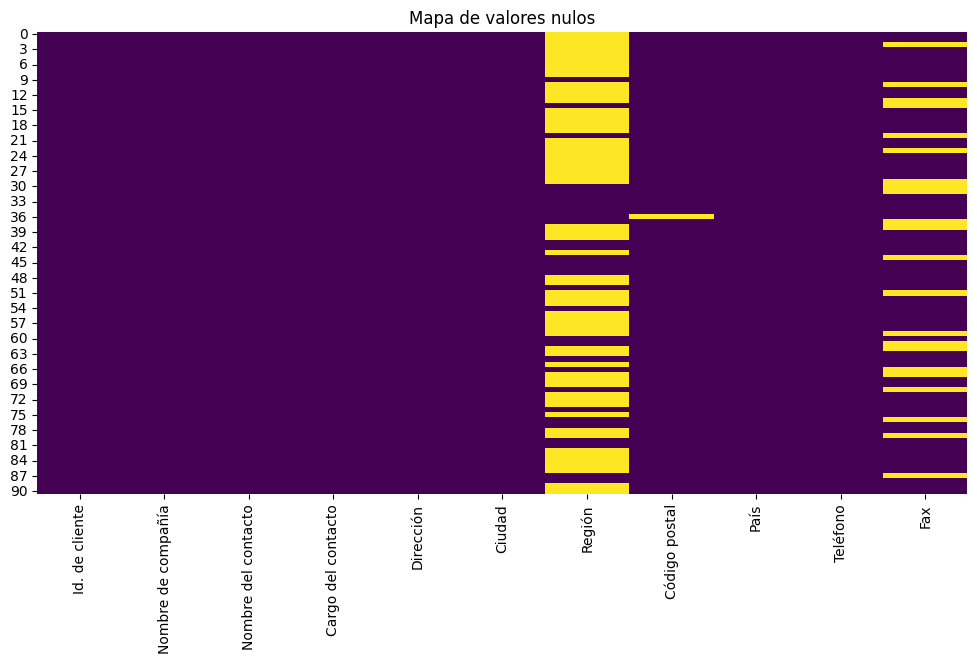

In [22]:
# Visualización de nulos
plt.figure(figsize=(12, 6))
sns.heatmap(df_clientes.isnull(), cbar=False, cmap='viridis')
plt.title('Mapa de valores nulos')
plt.show()

In [25]:
# DUPLICADOS
print(f"Filas duplicadas: {df_clientes.duplicated().sum()}")
# Si hay una columna ID/clave (ej. CUIT), revisá duplicados por esa columna puntual:
print(f"Duplicados por ID: {df_clientes.duplicated(subset=['Id. de cliente']).sum()}")

Filas duplicadas: 0
Duplicados por ID: 0


In [30]:
# ESTADÍSTICAS DESCRIPTIVAS
# Variables numéricas
#df_clientes.describe().T

# Variables categóricas
df_clientes.describe(include=['object']).T

,count,unique,top,freq
Id. de cliente,91,91,PEBER,1
Nombre de compañía,91,91,Petrolera Berlín,1
Nombre del contacto,91,91,Maria Anders,1
Cargo del contacto,91,20,Gerente de Estación de Servicio,5
Dirección,91,91,Obere Str. 57,1
Ciudad,91,70,Londres,6
Región,31,18,SP,6
Código postal,90,86,1010,3
País,91,21,Estados Unidos,13
Teléfono,91,91,030-0074321,1


In [32]:
# VARIABLES CATEGÓRICAS - CARDINALIDAD
cat_cols = df_clientes.select_dtypes(include='object').columns

for col in cat_cols:
    n_unique = df_clientes[col].nunique()
    print(f"{col}: {n_unique} valores únicos")
    if n_unique <= 15:
        print(df_clientes[col].value_counts(normalize=True).round(3) * 100)
    print("-" * 40)

Id. de cliente: 91 valores únicos
----------------------------------------
Nombre de compañía: 91 valores únicos
----------------------------------------
Nombre del contacto: 91 valores únicos
----------------------------------------
Cargo del contacto: 20 valores únicos
----------------------------------------
Dirección: 91 valores únicos
----------------------------------------
Ciudad: 70 valores únicos
----------------------------------------
Región: 18 valores únicos
----------------------------------------
Código postal: 86 valores únicos
----------------------------------------
País: 21 valores únicos
----------------------------------------
Teléfono: 91 valores únicos
----------------------------------------
Fax: 69 valores únicos
----------------------------------------


In [34]:
# DISTRIBUCIÓN DE VARIABLES NUMÉRICAS
#num_cols = df_clientes.select_dtypes(include=np.number).columns

#df_clientes[num_cols].hist(figsize=(14, 10), bins=30)
#plt.tight_layout()
#plt.show()

In [36]:
# OUTLIERS
#for col in numericas:
#    plt.figure(figsize=(8, 3))
    
#    sns.boxplot(
#        data=df_clientes,
#        x=col
#    )
    
#    plt.title(f'Boxplot de {col}')
#    plt.show()

###

### Categorías

In [81]:
df_categorias = pd.read_csv(ruta_categorias, sep=';', encoding='latin1')

In [9]:
# VISTA GENERAL
print(f"Dimensiones: {df_categorias.shape}")
df_categorias.head()

Dimensiones: (8, 3)


,IdCategoria,NombreCategoria,Imagen
0,1,Combustibles Líquidos,NaN
1,2,Lubricantes,NaN
2,3,GNC,NaN
3,4,Aditivos y Químicos,NaN
4,5,Repuestos,NaN


In [10]:
# ESTRUCTURA Y TIPOS DE DATOS
df_categorias.info()
print(df_categorias.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   IdCategoria      8 non-null      int64  
 1   NombreCategoria  8 non-null      object 
 2   Imagen           0 non-null      float64
dtypes: float64(1), int64(1), object(1)
memory usage: 324.0+ bytes
int64      1
object     1
float64    1
Name: count, dtype: int64


In [12]:
# VALORES NULOS

nulos = df_categorias.isnull().sum()

pct_nulos = (nulos / len(df_categorias)) * 100

resumen_nulos = pd.DataFrame({
    'nulos': nulos,
    'pct': pct_nulos.round(2)
})

resumen_nulos = (
    resumen_nulos[
        resumen_nulos['nulos'] > 0
    ]
    .sort_values('pct', ascending=False)
)

resumen_nulos

,nulos,pct
Imagen,8,100.0


In [13]:
# DUPLICADOS

print(f"Filas duplicadas: {df_categorias.duplicated().sum()}")

Filas duplicadas: 0


In [15]:
# DUPLICADOS POR CLAVE / ID
# Reemplazar 'COLUMNA_ID' por la clave correspondiente

print(
    f"Duplicados por ID: "
    f"{df_categorias.duplicated(subset=['IdCategoria']).sum()}"
)

Duplicados por ID: 0


In [16]:
# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES CATEGÓRICAS

df_categorias.describe(include=['object']).T

,count,unique,top,freq
NombreCategoria,8,8,Combustibles Líquidos,1


In [17]:
# VARIABLES CATEGÓRICAS - CARDINALIDAD

cat_cols = df_categorias.select_dtypes(include='object').columns

for col in cat_cols:

    n_unique = df_categorias[col].nunique()

    print(f"{col}: {n_unique} valores únicos")

    if n_unique <= 15:
        print(
            df_categorias[col]
            .value_counts(normalize=True, dropna=False)
            .round(3) * 100
        )

    print("-" * 40)

NombreCategoria: 8 valores únicos
NombreCategoria
Combustibles Líquidos    12.5
Lubricantes              12.5
GNC                      12.5
Aditivos y Químicos      12.5
Repuestos                12.5
Accesorios               12.5
Seguridad Industrial     12.5
Servicios Técnicos       12.5
Name: proportion, dtype: float64
----------------------------------------


### Detalles de Pedidos

In [82]:
df_detalles_de_pedidos = pd.read_csv(ruta_detalles_de_pedidos, sep=';', encoding='latin1') 

In [19]:
# VISTA GENERAL

print(f"Dimensiones: {df_detalles_de_pedidos.shape}")

df_detalles_de_pedidos.head()

Dimensiones: (5937, 7)


,Iddepedido,Producto,Cantidad,Descuento,Total,CostosDirectos,CostosIndirectos
0,8787,5,12,0.20,219.82,54.95,39.57
1,8788,7,15,0.00,482.63,120.66,86.87
2,8789,56,2,0.00,81.51,20.38,14.67
3,8790,16,60,0.25,842.18,210.55,151.59
4,8791,24,28,0.00,135.14,33.78,24.32


In [20]:
# ESTRUCTURA Y TIPOS DE DATOS

df_detalles_de_pedidos.info()

print("\nCantidad de columnas por tipo de dato:")
print(df_detalles_de_pedidos.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5937 entries, 0 to 5936
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Iddepedido        5937 non-null   int64  
 1   Producto          5937 non-null   int64  
 2   Cantidad          5937 non-null   int64  
 3   Descuento         5937 non-null   float64
 4   Total             5937 non-null   float64
 5   CostosDirectos    5937 non-null   float64
 6   CostosIndirectos  5937 non-null   float64
dtypes: float64(4), int64(3)
memory usage: 324.8 KB

Cantidad de columnas por tipo de dato:
float64    4
int64      3
Name: count, dtype: int64


In [21]:
# DUPLICADOS

print(f"Filas duplicadas: {df_detalles_de_pedidos.duplicated().sum()}")

Filas duplicadas: 0


In [ ]:
# DUPLICADOS POR CLAVE / ID
# Reemplazar 'COLUMNA_ID' por la clave correspondiente

print(
    f"Duplicados por ID: "
    f"{df_detalles_de_pedidos.duplicated(subset=['Iddepedido']).sum()}"
)

Duplicados por ID: 1325


No existen registros completamente duplicados en la tabla Detalles de Pedidos. 
Sin embargo, Iddepedido se repite en 1325 registros,
lo cual puede ser esperable debido a que un mismo pedido
 puede contener múltiples líneas de detalle.

In [24]:
# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES NUMÉRICAS

num_cols = df_detalles_de_pedidos.select_dtypes(include=np.number).columns

df_detalles_de_pedidos[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Iddepedido,5937.0,10995.400034,1192.947052,8787.00,10255.00,10826.00,11914.00,13398.00
Producto,5937.0,28.321880,19.038627,1.00,11.00,26.00,44.00,62.00
Cantidad,5937.0,23.856493,19.168346,1.00,10.00,20.00,30.00,130.00
Descuento,5937.0,0.055779,0.082909,0.00,0.00,0.00,0.10,0.25
Total,5937.0,414.718961,731.006022,1.85,84.41,209.88,479.12,15130.17
CostosDirectos,5937.0,103.680072,182.751517,0.46,21.10,52.47,119.78,3782.54
CostosIndirectos,5937.0,74.649424,131.581163,0.33,15.19,37.78,86.24,2723.43


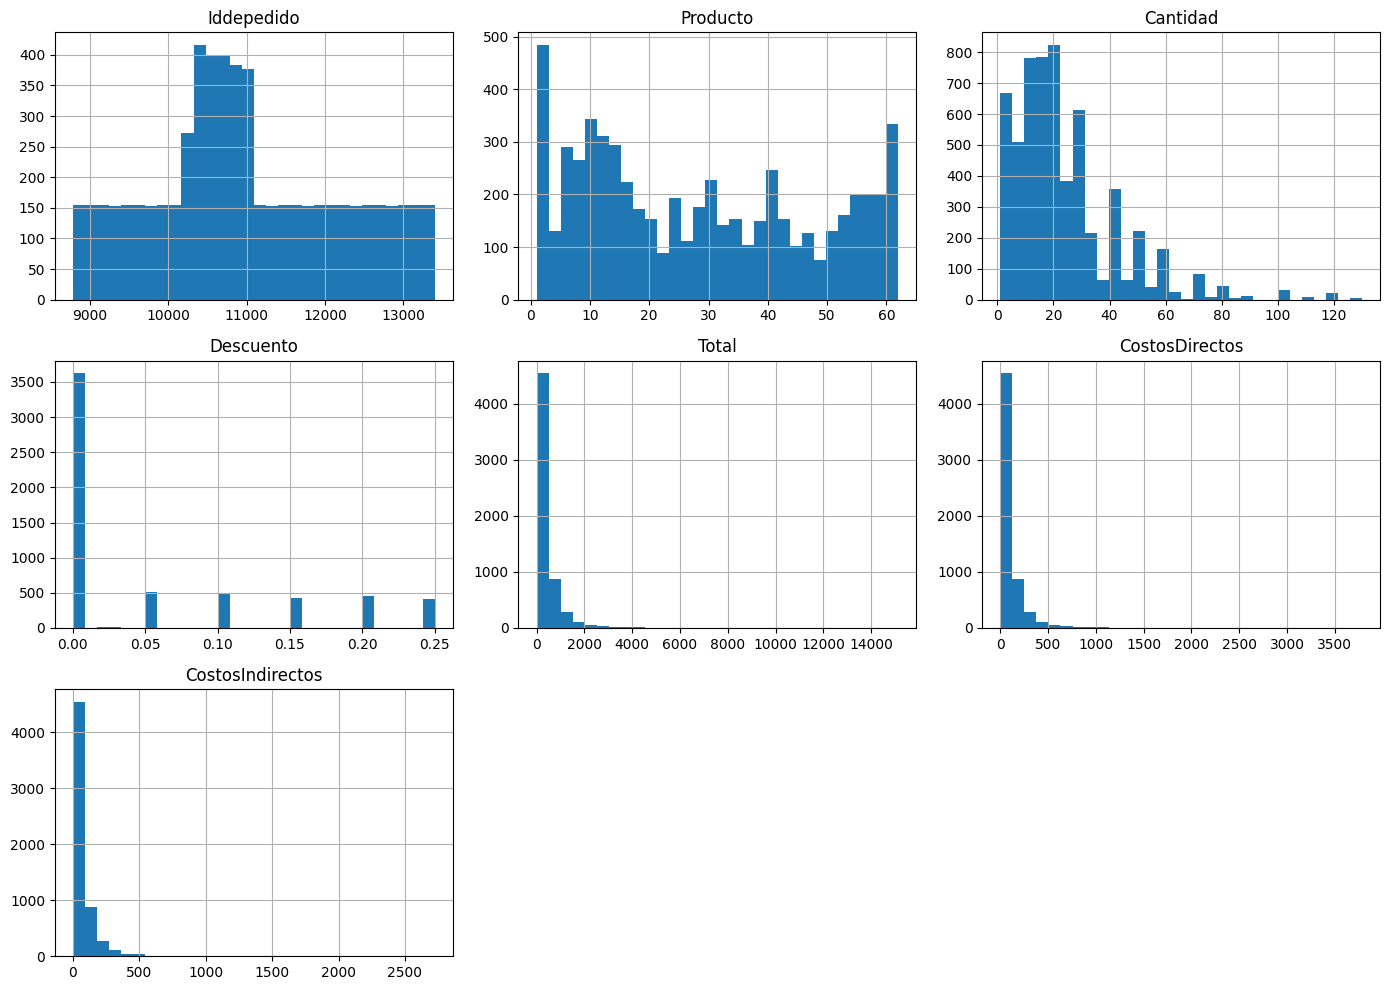

In [25]:
# DISTRIBUCIÓN DE VARIABLES NUMÉRICAS

df_detalles_de_pedidos[num_cols].hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()

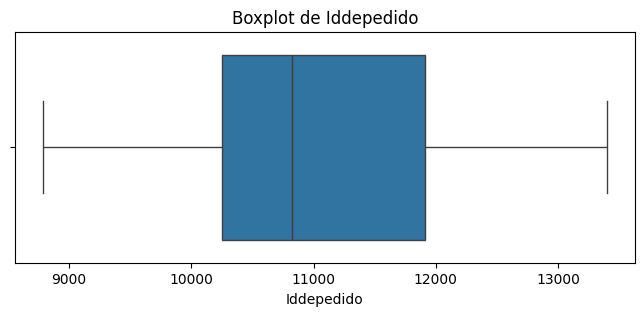

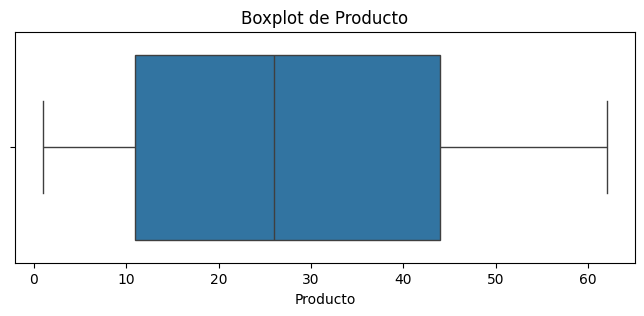

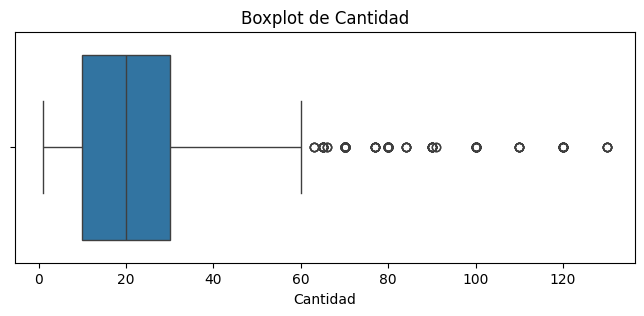

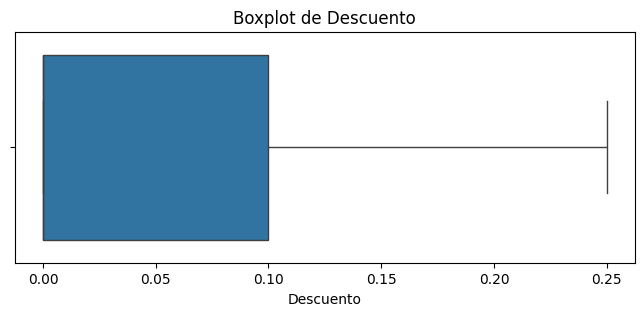

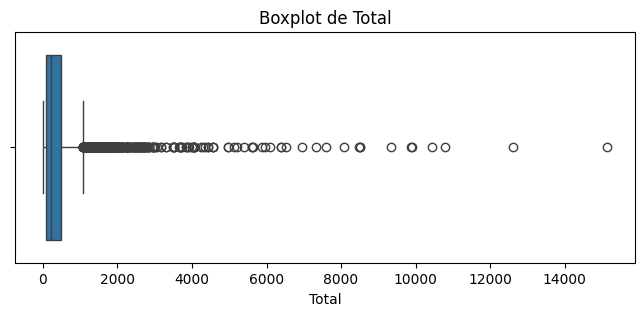

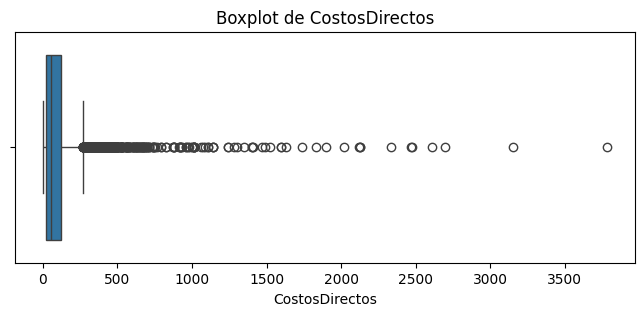

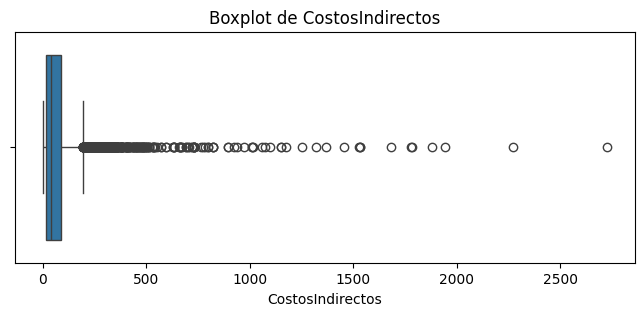

In [27]:
# OUTLIERS

for col in num_cols:

    plt.figure(figsize=(8, 3))

    sns.boxplot(
        data=df_detalles_de_pedidos,
        x=col
    )

    plt.title(f'Boxplot de {col}')
    plt.show()

### Empleados

In [83]:
df_empleados = pd.read_csv(ruta_empleados, encoding='latin1', sep=';')

In [8]:
# VISTA GENERAL

print(f"Dimensiones: {df_empleados.shape}")

df_empleados.head()

Dimensiones: (9, 16)


,Id. de empleado,Apellidos,Nombre,Cargo,Tratamiento,Fecha de nacimiento,Fecha de contratación,Dirección,Ciudad,Región,Código postal,País,Teléfono de domicilio,Extensión,Notas,Jefe
0,1,Davolio,Nancy,Representante de ventas,Srta.,08-dic-1968,01-may-1992,507 - 20th Ave. E.\nApt. 2A,Seattle,WA,98122,EE.UU.,(206) 555-9857,5467,Su formación incluye una licenciatura en Psico...,2.0
1,2,Fuller,Andrew,Vicepresidente comercial,Dr.,19-feb-1952,14-ago-1992,908 W. Capital Way,Tacoma,WA,98401,EE.UU.,(206) 555-9482,3457,Andrew completó su licenciatura en Comercio y ...,NaN
2,3,Leverling,Janet,Representante de ventas,Srta.,30-ago-1963,01-abr-1992,722 Moss Bay Blvd.,Kirkland,WA,98033,EE.UU.,(206) 555-3412,3355,Janet es licenciada en Química por la Universi...,2.0
3,4,Peacock,Margaret,Representante de ventas,Sra.,19-sept-1958,03-may-1993,4110 Old Redmond Rd.,Redmond,WA,98052,EE.UU.,(206) 555-8122,5176,Margaret esta enfocada en la negociación de co...,2.0
4,5,Buchanan,Steven,Gerente de ventas,Sr.,04-mar-1955,17-oct-1993,14 Garrett Hill,Londres,NaN,SW1 8JR,Reino Unido,(71) 555-4848,3453,Steven Buchanan se graduó en la Universidad de...,2.0


In [9]:

# ESTRUCTURA Y TIPOS DE DATOS

df_empleados.info()

print("\nCantidad de columnas por tipo de dato:")
print(df_empleados.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Id. de empleado        9 non-null      int64  
 1   Apellidos              9 non-null      object 
 2   Nombre                 9 non-null      object 
 3   Cargo                  9 non-null      object 
 4   Tratamiento            9 non-null      object 
 5   Fecha de nacimiento    9 non-null      object 
 6   Fecha de contratación  9 non-null      object 
 7   Dirección              9 non-null      object 
 8   Ciudad                 9 non-null      object 
 9   Región                 5 non-null      object 
 10  Código postal          9 non-null      object 
 11  País                   9 non-null      object 
 12  Teléfono de domicilio  9 non-null      object 
 13  Extensión              9 non-null      int64  
 14  Notas                  9 non-null      object 
 15  Jefe      

In [10]:
# VALORES NULOS

nulos = df_empleados.isnull().sum()

pct_nulos = (nulos / len(df_empleados)) * 100

resumen_nulos = pd.DataFrame({
    'nulos': nulos,
    'pct': pct_nulos.round(2)
})

resumen_nulos = (
    resumen_nulos[
        resumen_nulos['nulos'] > 0
    ]
    .sort_values('pct', ascending=False)
)

resumen_nulos

,nulos,pct
Región,4,44.44
Jefe,1,11.11


In [11]:
# DUPLICADOS

print(f"Filas duplicadas: {df_empleados.duplicated().sum()}")

Filas duplicadas: 0


In [13]:

# DUPLICADOS POR CLAVE / ID
# Reemplazar 'COLUMNA_ID' por la clave correspondiente

print(
    f"Duplicados por ID: "
    f"{df_empleados.duplicated(subset=['Id. de empleado']).sum()}"
)
     

Duplicados por ID: 0


In [14]:
# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES NUMÉRICAS

num_cols = df_empleados.select_dtypes(include=np.number).columns

df_empleados[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Id. de empleado,9.0,5.000,2.738613,1.0,3.0,5.0,7.0,9.0
Extensión,9.0,2733.000,1958.430366,428.0,465.0,3355.0,3457.0,5467.0
Jefe,8.0,3.125,1.552648,2.0,2.0,2.0,5.0,5.0


In [15]:
# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES CATEGÓRICAS

df_empleados.describe(include=['object']).T

,count,unique,top,freq
Apellidos,9,9,Davolio,1
Nombre,9,9,Nancy,1
Cargo,9,4,Representante de ventas,6
Tratamiento,9,4,Srta.,4
Fecha de nacimiento,9,9,08-dic-1968,1
Fecha de contratación,9,8,17-oct-1993,2
Dirección,9,9,507 - 20th Ave. E.\nApt. 2A,1
Ciudad,9,5,Londres,4
Región,5,1,WA,5
Código postal,9,9,98122,1


In [16]:
# VARIABLES CATEGÓRICAS - CARDINALIDAD

cat_cols = df_empleados.select_dtypes(include='object').columns

for col in cat_cols:

    n_unique = df_empleados[col].nunique()

    print(f"{col}: {n_unique} valores únicos")

    if n_unique <= 15:
        print(
            df_empleados[col]
            .value_counts(normalize=True, dropna=False)
            .round(3) * 100
        )

    print("-" * 40)

Apellidos: 9 valores únicos
Apellidos
Davolio      11.1
Fuller       11.1
Leverling    11.1
Peacock      11.1
Buchanan     11.1
Suyama       11.1
King         11.1
Callahan     11.1
Dodsworth    11.1
Name: proportion, dtype: float64
----------------------------------------
Nombre: 9 valores únicos
Nombre
Nancy       11.1
Andrew      11.1
Janet       11.1
Margaret    11.1
Steven      11.1
Michael     11.1
Robert      11.1
Laura       11.1
Anne        11.1
Name: proportion, dtype: float64
----------------------------------------
Cargo: 4 valores únicos
Cargo
Representante de ventas       66.7
Vicepresidente comercial      11.1
Gerente de ventas             11.1
Coordinador ventas interno    11.1
Name: proportion, dtype: float64
----------------------------------------
Tratamiento: 4 valores únicos
Tratamiento
Srta.    44.4
Sr.      33.3
Dr.      11.1
Sra.     11.1
Name: proportion, dtype: float64
----------------------------------------
Fecha de nacimiento: 9 valores únicos
Fecha de naci

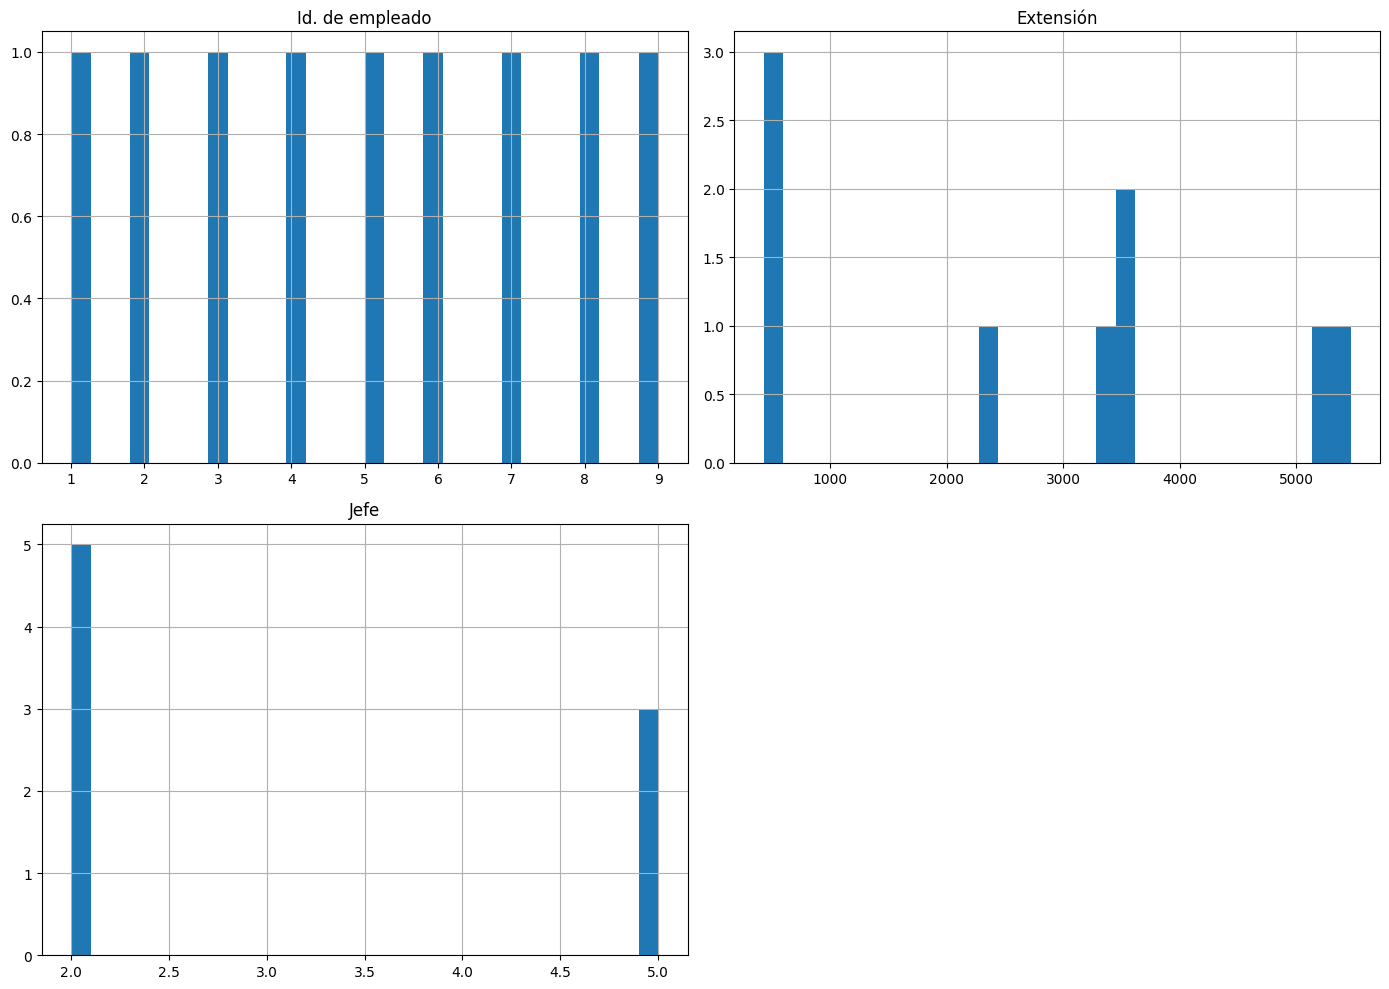

In [17]:
# DISTRIBUCIÓN DE VARIABLES NUMÉRICAS

df_empleados[num_cols].hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()

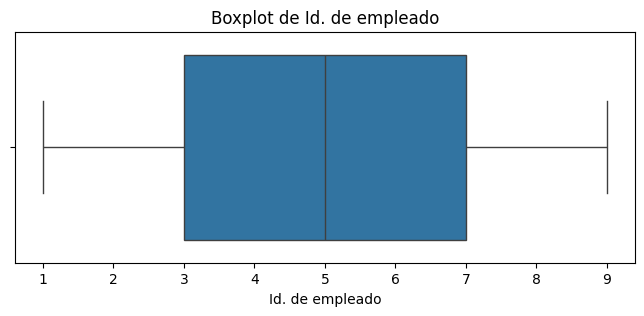

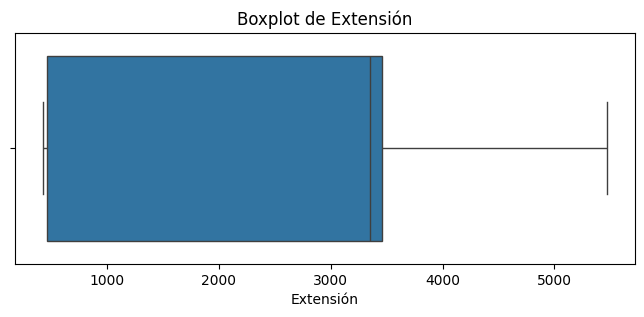

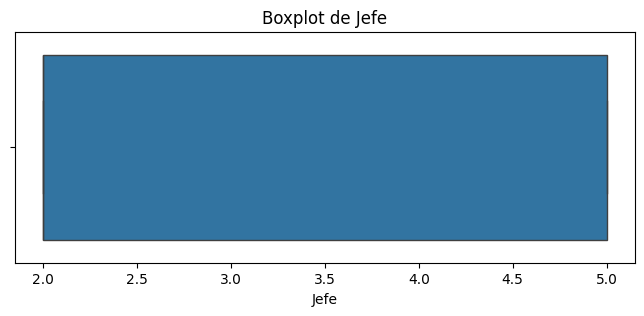

In [19]:

# OUTLIERS

for col in num_cols:

    plt.figure(figsize=(8, 3))

    sns.boxplot(
        data=df_empleados,
        x=col
    )

    plt.title(f'Boxplot de {col}')
    plt.show()

### Equipos

In [20]:
df_equipos = pd.read_csv(ruta_equipos, encoding='latin1', sep=';')

In [21]:
# VISTA GENERAL

print(f"Dimensiones: {df_equipos.shape}")

df_equipos.head()

Dimensiones: (30, 5)


,IdEquipo,IdEstacion,TipoEquipo,Modelo,Estado
0,1,7,Medidor,EQ-1001,Operativo
1,2,10,Surtidor,EQ-1002,En mantenimiento
2,3,5,Tanque,EQ-1003,En mantenimiento
3,4,10,Compresor GNC,EQ-1004,En mantenimiento
4,5,9,Bomba,EQ-1005,En mantenimiento


In [22]:

# ESTRUCTURA Y TIPOS DE DATOS

df_equipos.info()

print("\nCantidad de columnas por tipo de dato:")
print(df_equipos.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   IdEquipo    30 non-null     int64 
 1   IdEstacion  30 non-null     int64 
 2   TipoEquipo  30 non-null     object
 3   Modelo      30 non-null     object
 4   Estado      30 non-null     object
dtypes: int64(2), object(3)
memory usage: 1.3+ KB

Cantidad de columnas por tipo de dato:
object    3
int64     2
Name: count, dtype: int64


In [27]:
# DUPLICADOS

print(f"Filas duplicadas: {df_equipos.duplicated().sum()}")

Filas duplicadas: 0


In [28]:

# DUPLICADOS POR CLAVE / ID
# Reemplazar 'COLUMNA_ID' por la clave correspondiente

print(
    f"Duplicados por ID: "
    f"{df_equipos.duplicated(subset=['IdEquipo']).sum()}"
)
     

Duplicados por ID: 0


In [30]:

# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES CATEGÓRICAS

df_equipos.describe(include=['object']).T

,count,unique,top,freq
TipoEquipo,30,5,Medidor,9
Modelo,30,30,EQ-1001,1
Estado,30,2,Operativo,15


In [31]:
# VARIABLES CATEGÓRICAS - CARDINALIDAD

cat_cols = df_equipos.select_dtypes(include='object').columns

for col in cat_cols:

    n_unique = df_equipos[col].nunique()

    print(f"{col}: {n_unique} valores únicos")

    if n_unique <= 15:
        print(
            df_equipos[col]
            .value_counts(normalize=True, dropna=False)
            .round(3) * 100
        )

    print("-" * 40)

TipoEquipo: 5 valores únicos
TipoEquipo
Medidor          30.0
Bomba            26.7
Tanque           16.7
Compresor GNC    16.7
Surtidor         10.0
Name: proportion, dtype: float64
----------------------------------------
Modelo: 30 valores únicos
----------------------------------------
Estado: 2 valores únicos
Estado
Operativo           50.0
En mantenimiento    50.0
Name: proportion, dtype: float64
----------------------------------------


### Estaciones

In [32]:
df_estaciones = pd.read_csv(ruta_estaciones, sep=';', encoding='latin1')

In [33]:
# VISTA GENERAL

print(f"Dimensiones: {df_estaciones.shape}")

df_estaciones.head()

Dimensiones: (10, 6)


,IdEstacion,NombreEstacion,Ciudad,Provincia,Tipo,FechaApertura
0,1,DATAFUEL CÃ³rdoba,CÃ³rdoba,CÃ³rdoba,Propia,2004-09-23
1,2,DATAFUEL Buenos,Buenos Aires,Buenos Aires,Franquicia,2005-07-22
2,3,DATAFUEL Santa,Santa Fe,Santa Fe,Propia,2003-06-02
3,4,DATAFUEL Mendoza,Mendoza,Mendoza,Franquicia,2007-12-14
4,5,DATAFUEL Salta,Salta,Salta,Propia,2004-06-07


In [34]:
# ESTRUCTURA Y TIPOS DE DATOS

df_estaciones.info()

print("\nCantidad de columnas por tipo de dato:")
print(df_estaciones.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   IdEstacion      10 non-null     int64 
 1   NombreEstacion  10 non-null     object
 2   Ciudad          10 non-null     object
 3   Provincia       10 non-null     object
 4   Tipo            10 non-null     object
 5   FechaApertura   10 non-null     object
dtypes: int64(1), object(5)
memory usage: 612.0+ bytes

Cantidad de columnas por tipo de dato:
object    5
int64     1
Name: count, dtype: int64


In [35]:
# DUPLICADOS

print(f"Filas duplicadas: {df_estaciones.duplicated().sum()}")

Filas duplicadas: 0


In [36]:
# DUPLICADOS POR CLAVE / ID
# Reemplazar 'COLUMNA_ID' por la clave correspondiente

print(
    f"Duplicados por ID: "
    f"{df_estaciones.duplicated(subset=['IdEstacion']).sum()}"
)

Duplicados por ID: 0


In [39]:
# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES CATEGÓRICAS

df_estaciones.describe(include=['object']).T

,count,unique,top,freq
NombreEstacion,10,10,DATAFUEL CÃ³rdoba,1
Ciudad,10,10,CÃ³rdoba,1
Provincia,10,10,CÃ³rdoba,1
Tipo,10,2,Propia,5
FechaApertura,10,10,2004-09-23,1


In [40]:
# VARIABLES CATEGÓRICAS - CARDINALIDAD

cat_cols = df_estaciones.select_dtypes(include='object').columns

for col in cat_cols:

    n_unique = df_estaciones[col].nunique()

    print(f"{col}: {n_unique} valores únicos")

    if n_unique <= 15:
        print(
            df_estaciones[col]
            .value_counts(normalize=True, dropna=False)
            .round(3) * 100
        )

    print("-" * 40)

NombreEstacion: 10 valores únicos
NombreEstacion
DATAFUEL CÃ³rdoba    10.0
DATAFUEL Buenos      10.0
DATAFUEL Santa       10.0
DATAFUEL Mendoza     10.0
DATAFUEL Salta       10.0
DATAFUEL NeuquÃ©n    10.0
DATAFUEL TucumÃ¡n    10.0
DATAFUEL Entre       10.0
DATAFUEL La          10.0
DATAFUEL San         10.0
Name: proportion, dtype: float64
----------------------------------------
Ciudad: 10 valores únicos
Ciudad
CÃ³rdoba        10.0
Buenos Aires    10.0
Santa Fe        10.0
Mendoza         10.0
Salta           10.0
NeuquÃ©n        10.0
TucumÃ¡n        10.0
Entre RÃ­os     10.0
La Pampa        10.0
San Juan        10.0
Name: proportion, dtype: float64
----------------------------------------
Provincia: 10 valores únicos
Provincia
CÃ³rdoba        10.0
Buenos Aires    10.0
Santa Fe        10.0
Mendoza         10.0
Salta           10.0
NeuquÃ©n        10.0
TucumÃ¡n        10.0
Entre RÃ­os     10.0
La Pampa        10.0
San Juan        10.0
Name: proportion, dtype: float64
------------------

### Mantenimientos

In [41]:

df_mantenimientos = pd.read_csv(ruta_mantenimientos, sep=';', encoding='latin1')

In [44]:
# VISTA GENERAL

print(f"Dimensiones: {df_mantenimientos.shape}")

df_mantenimientos.head()

Dimensiones: (50, 5)


,IdMantenimiento,IdEquipo,FechaMantenimiento,TipoMantenimiento,Costo
0,18,4,2009-04-10,Correctivo,48750
1,22,17,2009-06-19,CalibraciÃ³n,129682
2,36,13,2009-11-17,CalibraciÃ³n,45050
3,29,14,2010-02-26,Reemplazo de componentes,29987
4,4,26,2010-04-23,Reemplazo de componentes,128057


In [45]:
# ESTRUCTURA Y TIPOS DE DATOS

df_mantenimientos.info()

print("\nCantidad de columnas por tipo de dato:")
print(df_mantenimientos.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   IdMantenimiento     50 non-null     int64 
 1   IdEquipo            50 non-null     int64 
 2   FechaMantenimiento  50 non-null     object
 3   TipoMantenimiento   50 non-null     object
 4   Costo               50 non-null     int64 
dtypes: int64(3), object(2)
memory usage: 2.1+ KB

Cantidad de columnas por tipo de dato:
int64     3
object    2
Name: count, dtype: int64


In [46]:

# DUPLICADOS

print(f"Filas duplicadas: {df_mantenimientos.duplicated().sum()}")

Filas duplicadas: 0


In [47]:

# DUPLICADOS POR CLAVE / ID
# Reemplazar 'COLUMNA_ID' por la clave correspondiente

print(
    f"Duplicados por ID: "
    f"{df_mantenimientos.duplicated(subset=['IdMantenimiento']).sum()}"
)

Duplicados por ID: 0


In [48]:
# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES NUMÉRICAS

num_cols = df_mantenimientos.select_dtypes(include=np.number).columns

df_mantenimientos[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
IdMantenimiento,50.0,25.50,14.577380,1.0,13.25,25.5,37.75,50.0
IdEquipo,50.0,15.06,8.165157,1.0,8.25,14.5,22.00,29.0
Costo,50.0,88587.52,48061.202635,20478.0,45131.75,84206.0,133489.00,170430.0


In [49]:

# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES CATEGÓRICAS

df_mantenimientos.describe(include=['object']).T

,count,unique,top,freq
FechaMantenimiento,50,50,2009-04-10,1
TipoMantenimiento,50,5,CalibraciÃ³n,12


In [50]:

# VARIABLES CATEGÓRICAS - CARDINALIDAD

cat_cols = df_mantenimientos.select_dtypes(include='object').columns

for col in cat_cols:

    n_unique = df_mantenimientos[col].nunique()

    print(f"{col}: {n_unique} valores únicos")

    if n_unique <= 15:
        print(
            df_mantenimientos[col]
            .value_counts(normalize=True, dropna=False)
            .round(3) * 100
        )

    print("-" * 40)

FechaMantenimiento: 50 valores únicos
----------------------------------------
TipoMantenimiento: 5 valores únicos
TipoMantenimiento
CalibraciÃ³n                24.0
Correctivo                  22.0
InspecciÃ³n                 20.0
Reemplazo de componentes    18.0
Preventivo                  16.0
Name: proportion, dtype: float64
----------------------------------------


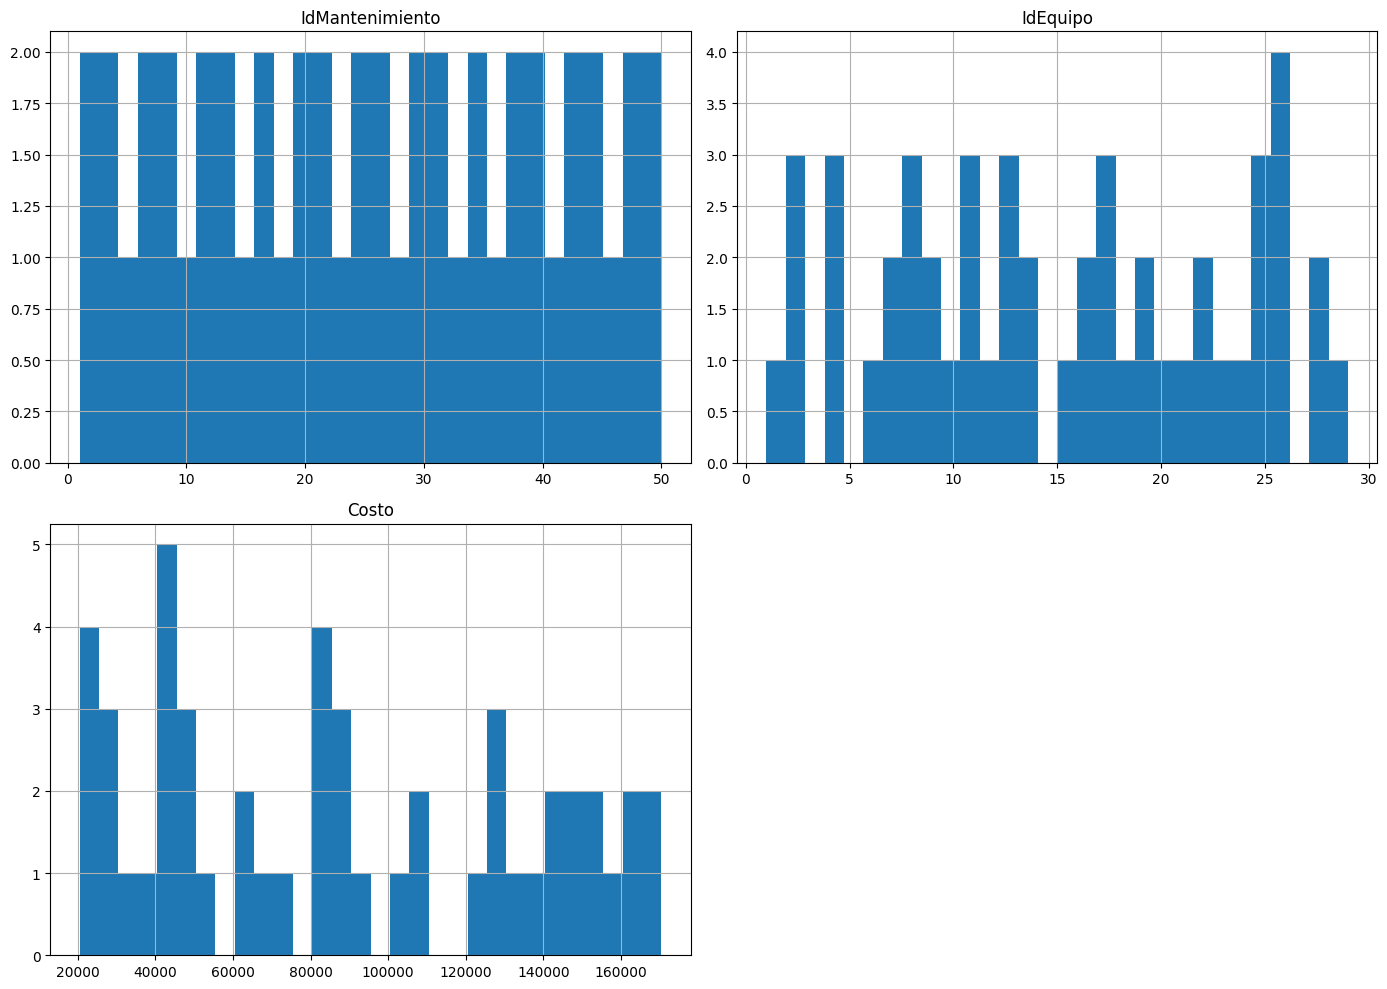

In [51]:

# DISTRIBUCIÓN DE VARIABLES NUMÉRICAS

df_mantenimientos[num_cols].hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()

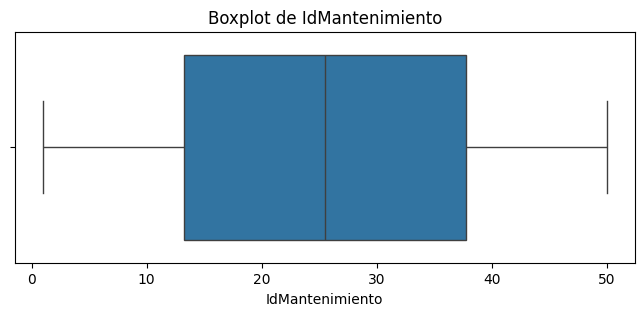

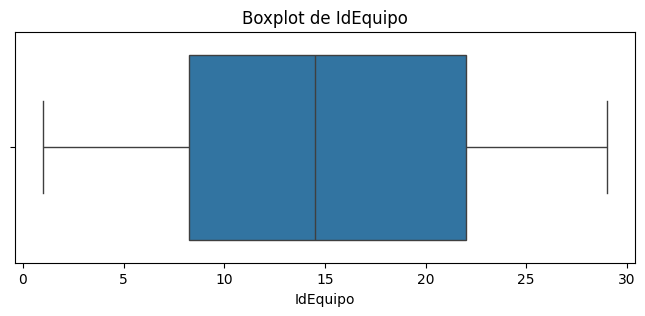

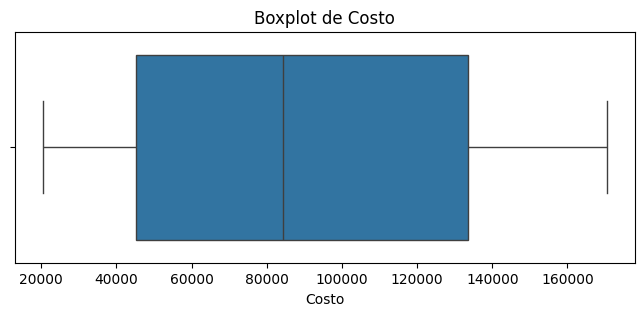

In [52]:
# OUTLIERS

for col in num_cols:

    plt.figure(figsize=(8, 3))

    sns.boxplot(
        data=df_mantenimientos,
        x=col
    )

    plt.title(f'Boxplot de {col}')
    plt.show()

### Pedidos

In [53]:

df_pedidos = pd.read_csv(ruta_pedidos, sep=';', encoding='latin1')

In [54]:
# VISTA GENERAL

print(f"Dimensiones: {df_pedidos.shape}")

df_pedidos.head()

Dimensiones: (4612, 6)


,Id# de pedido,Cliente,Empleado,Fecha de pedido,Forma de env?,Fecha de entrega
0,8787,PEBER,1,2/1/2009 00:00,3,7/1/2009
1,8788,DICOM,1,2/1/2009 00:00,1,7/1/2009
2,8789,ESSER,8,2/1/2009 00:00,2,7/1/2009
3,8790,GALON,4,3/1/2009 00:00,3,8/1/2009
4,8791,TECOM,2,3/1/2009 00:00,1,8/1/2009


In [55]:

# ESTRUCTURA Y TIPOS DE DATOS

df_pedidos.info()

print("\nCantidad de columnas por tipo de dato:")
print(df_pedidos.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4612 entries, 0 to 4611
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Id# de pedido     4612 non-null   int64 
 1   Cliente           4612 non-null   object
 2   Empleado          4612 non-null   int64 
 3   Fecha de pedido   4612 non-null   object
 4   Forma de env?     4612 non-null   int64 
 5   Fecha de entrega  4612 non-null   object
dtypes: int64(3), object(3)
memory usage: 216.3+ KB

Cantidad de columnas por tipo de dato:
int64     3
object    3
Name: count, dtype: int64


In [56]:
# DUPLICADOS

print(f"Filas duplicadas: {df_pedidos.duplicated().sum()}")

Filas duplicadas: 0


In [57]:

# DUPLICADOS POR CLAVE / ID
# Reemplazar 'COLUMNA_ID' por la clave correspondiente

print(
    f"Duplicados por ID: "
    f"{df_pedidos.duplicated(subset=['Id# de pedido']).sum()}"
)
     

Duplicados por ID: 0


In [58]:

# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES CATEGÓRICAS

df_pedidos.describe(include=['object']).T

,count,unique,top,freq
Cliente,4612,91,PEBER,51
Fecha de pedido,4612,3080,26/2/2015 00:00,6
Fecha de entrega,4612,2493,11/4/2015,8


In [59]:
# VARIABLES CATEGÓRICAS - CARDINALIDAD

cat_cols = df_pedidos.select_dtypes(include='object').columns

for col in cat_cols:

    n_unique = df_pedidos[col].nunique()

    print(f"{col}: {n_unique} valores únicos")

    if n_unique <= 15:
        print(
            df_pedidos[col]
            .value_counts(normalize=True, dropna=False)
            .round(3) * 100
        )

    print("-" * 40)

Cliente: 91 valores únicos
----------------------------------------
Fecha de pedido: 3080 valores únicos
----------------------------------------
Fecha de entrega: 2493 valores únicos
----------------------------------------


### Productos

In [60]:

df_productos = pd.read_csv(ruta_productos, sep=';', encoding='latin1')

In [62]:
# VISTA GENERAL

print(f"Dimensiones: {df_productos.shape}")

df_productos.head()

Dimensiones: (62, 10)


,Id. de producto,Nombre de producto,Proveedor,Categoria,Cantidad por unidad,Precio por unidad,Unidades en existencia,Unidades pedidas,Nivel de nuevo pedido,Suspendido
0,1,Gasoil Grado 3 (Premium),1,1,10 cajas x 20 bolsas,"29,70",39,0,10,FALSO
1,2,Fuel Oil para Turbinas,1,1,24 - bot. 12 l,"31,35",17,40,25,FALSO
2,3,Aceite SintÃ©tico de Turbina ISO 32,1,2,12 - bot. 550 ml,"16,50",13,70,25,FALSO
3,4,Grasa de Alta Temperatura EP2,1,2,48 - frascos 6 l,"36,30",53,0,0,FALSO
4,5,Lubricante DielÃ©ctrico para Transformadores,1,2,36 cajas,"35,23",0,0,0,VERDADERO


In [63]:
# ESTRUCTURA Y TIPOS DE DATOS

df_productos.info()

print("\nCantidad de columnas por tipo de dato:")
print(df_productos.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Id. de producto         62 non-null     int64 
 1   Nombre de producto      62 non-null     object
 2   Proveedor               62 non-null     int64 
 3   Categoria               62 non-null     int64 
 4   Cantidad por unidad     62 non-null     object
 5   Precio por unidad       62 non-null     object
 6   Unidades en existencia  62 non-null     int64 
 7   Unidades pedidas        62 non-null     int64 
 8   Nivel de nuevo pedido   62 non-null     int64 
 9   Suspendido              62 non-null     object
dtypes: int64(6), object(4)
memory usage: 5.0+ KB

Cantidad de columnas por tipo de dato:
int64     6
object    4
Name: count, dtype: int64


In [65]:
# DUPLICADOS

print(f"Filas duplicadas: {df_productos.duplicated().sum()}")

Filas duplicadas: 0


In [66]:

# DUPLICADOS POR CLAVE / ID
# Reemplazar 'COLUMNA_ID' por la clave correspondiente

print(
    f"Duplicados por ID: "
    f"{df_productos.duplicated(subset=['Id. de producto']).sum()}"
)

Duplicados por ID: 0


In [67]:
# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES NUMÉRICAS

num_cols = df_productos.select_dtypes(include=np.number).columns

df_productos[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Id. de producto,62.0,31.500000,18.041619,1.0,16.25,31.5,46.75,62.0
Proveedor,62.0,2.693548,1.499603,1.0,1.00,3.0,4.00,5.0
Categoria,62.0,3.596774,2.398495,1.0,2.00,3.0,4.00,8.0
Unidades en existencia,62.0,38.161290,35.325277,0.0,15.00,23.0,52.75,123.0
Unidades pedidas,62.0,5.967742,18.238823,0.0,0.00,0.0,0.00,100.0
Nivel de nuevo pedido,62.0,12.741935,11.002139,0.0,0.00,15.0,25.00,30.0


Nota: 'Id. de producto', 'Proveedor' y 'Categoria' son códigos identificadores,
no variables numéricas continuas. Aunque describe() las muestre como numéricas,
deben tratarse como categóricas.

In [68]:
# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES CATEGÓRICAS

df_productos.describe(include=['object']).T

,count,unique,top,freq
Nombre de producto,62,59,Inhibidor de CorrosiÃ³n QuÃ­mico,2
Cantidad por unidad,62,48,24 - paq. 250 g,3
Precio por unidad,62,46,"29,70",4
Suspendido,62,2,FALSO,59


A la hora de realizar en cuenta el análisis con SQL, tener en cuenta el tipo de dato de 'Precio por Unidad'. 

In [69]:
# VARIABLES CATEGÓRICAS - CARDINALIDAD

cat_cols = df_productos.select_dtypes(include='object').columns

for col in cat_cols:

    n_unique = df_productos[col].nunique()

    print(f"{col}: {n_unique} valores únicos")

    if n_unique <= 15:
        print(
            df_productos[col]
            .value_counts(normalize=True, dropna=False)
            .round(3) * 100
        )

    print("-" * 40)

Nombre de producto: 59 valores únicos
----------------------------------------
Cantidad por unidad: 48 valores únicos
----------------------------------------
Precio por unidad: 46 valores únicos
----------------------------------------
Suspendido: 2 valores únicos
Suspendido
FALSO        95.2
VERDADERO     4.8
Name: proportion, dtype: float64
----------------------------------------


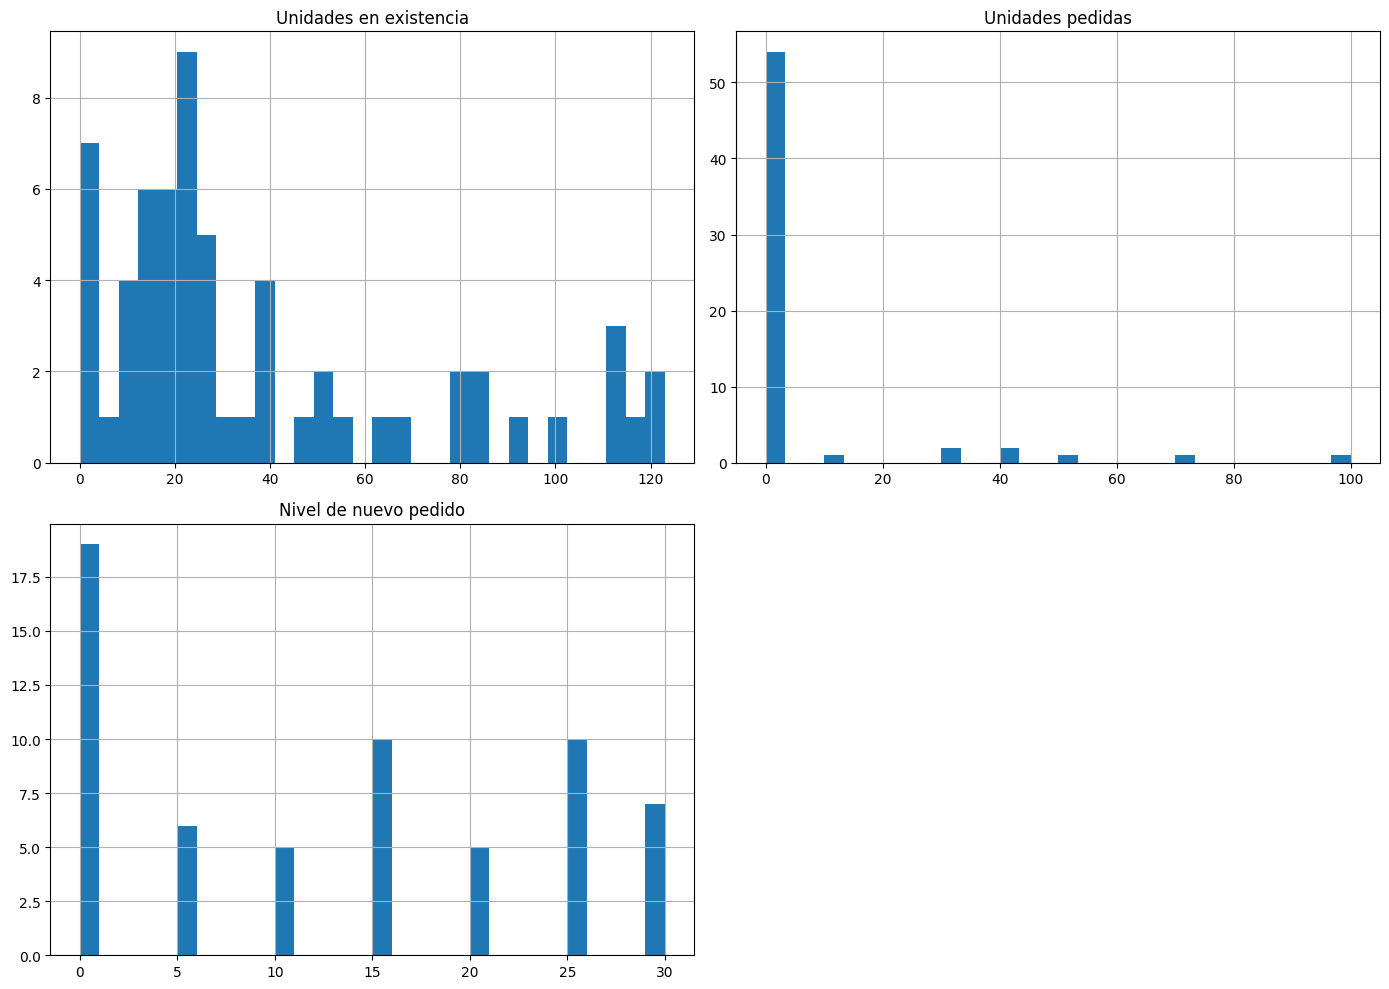

In [71]:
# DISTRIBUCIÓN DE VARIABLES NUMÉRICAS

cols_realmente_numericas = ['Unidades en existencia', 'Unidades pedidas', 'Nivel de nuevo pedido']

df_productos[cols_realmente_numericas].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

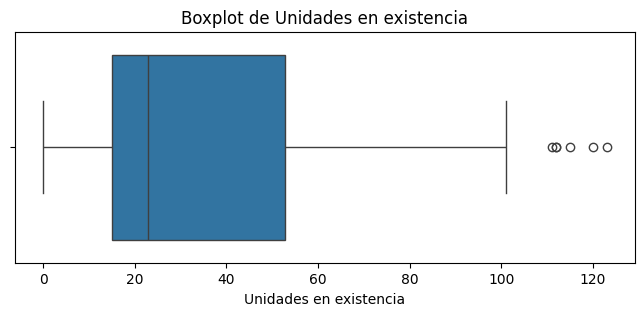

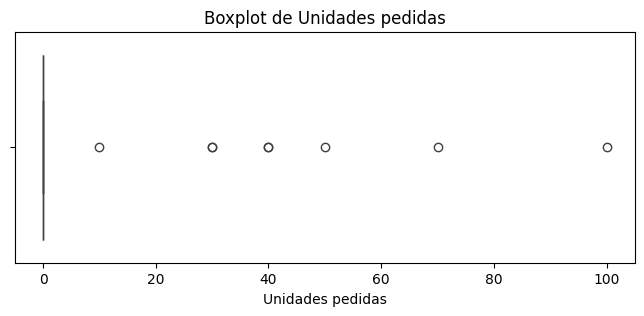

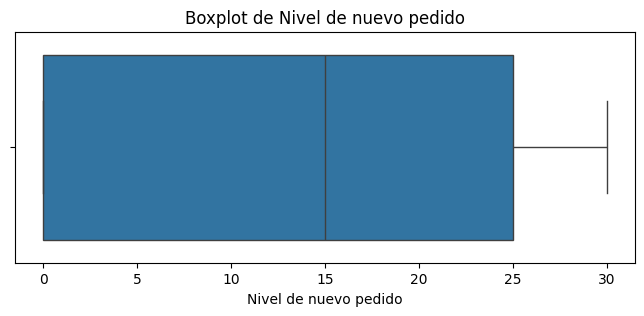

In [72]:
# OUTLIERS

for col in cols_realmente_numericas:

    plt.figure(figsize=(8, 3))

    sns.boxplot(
        data=df_productos,
        x=col
    )

    plt.title(f'Boxplot de {col}')
    plt.show()

### Proveedores

In [73]:

df_proveedores = pd.read_csv(ruta_proveedores, sep=';', encoding='latin1')

In [74]:

# VISTA GENERAL

print(f"Dimensiones: {df_proveedores.shape}")

df_proveedores.head()

Dimensiones: (10, 5)


,IdProveedor,NombreProveedor,Ciudad,Telefono,Email
0,1,YPF LogÃ­stica,Buenos Aires,35141000,contacto1@proveedor.com
1,2,Shell Supply,CÃ³rdoba,35141001,contacto2@proveedor.com
2,3,Axion Energy,Rosario,35141002,contacto3@proveedor.com
3,4,Petrobras,Mendoza,35141003,contacto4@proveedor.com
4,5,LubriTech,CÃ³rdoba,35141004,contacto5@proveedor.com


In [75]:
# ESTRUCTURA Y TIPOS DE DATOS

df_proveedores.info()

print("\nCantidad de columnas por tipo de dato:")
print(df_proveedores.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   IdProveedor      10 non-null     int64 
 1   NombreProveedor  10 non-null     object
 2   Ciudad           10 non-null     object
 3   Telefono         10 non-null     int64 
 4   Email            10 non-null     object
dtypes: int64(2), object(3)
memory usage: 532.0+ bytes

Cantidad de columnas por tipo de dato:
object    3
int64     2
Name: count, dtype: int64


El tipo de dato de 'Telefono' debe ser object. Tenerlo en cuenta a la hora del análisis en SQL.

In [76]:
# DUPLICADOS

print(f"Filas duplicadas: {df_proveedores.duplicated().sum()}")

Filas duplicadas: 0


In [77]:
# DUPLICADOS POR CLAVE / ID
# Reemplazar 'COLUMNA_ID' por la clave correspondiente

print(
    f"Duplicados por ID: "
    f"{df_proveedores.duplicated(subset=['IdProveedor']).sum()}"
)

Duplicados por ID: 0


In [78]:
# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES CATEGÓRICAS

df_proveedores.describe(include=['object']).T

,count,unique,top,freq
NombreProveedor,10,10,YPF LogÃ­stica,1
Ciudad,10,7,Buenos Aires,2
Email,10,10,contacto1@proveedor.com,1


In [79]:
# VARIABLES CATEGÓRICAS - CARDINALIDAD

cat_cols = df_proveedores.select_dtypes(include='object').columns

for col in cat_cols:

    n_unique = df_proveedores[col].nunique()

    print(f"{col}: {n_unique} valores únicos")

    if n_unique <= 15:
        print(
            df_proveedores[col]
            .value_counts(normalize=True, dropna=False)
            .round(3) * 100
        )

    print("-" * 40)

NombreProveedor: 10 valores únicos
NombreProveedor
YPF LogÃ­stica      10.0
Shell Supply        10.0
Axion Energy        10.0
Petrobras           10.0
LubriTech           10.0
ValvePro            10.0
TankSystems         10.0
Industrial Pumps    10.0
GasControl          10.0
TecnoOil            10.0
Name: proportion, dtype: float64
----------------------------------------
Ciudad: 7 valores únicos
Ciudad
Buenos Aires     20.0
CÃ³rdoba         20.0
Rosario          20.0
Mendoza          10.0
BahÃ­a Blanca    10.0
NeuquÃ©n         10.0
Salta            10.0
Name: proportion, dtype: float64
----------------------------------------
Email: 10 valores únicos
Email
contacto1@proveedor.com     10.0
contacto2@proveedor.com     10.0
contacto3@proveedor.com     10.0
contacto4@proveedor.com     10.0
contacto5@proveedor.com     10.0
contacto6@proveedor.com     10.0
contacto7@proveedor.com     10.0
contacto8@proveedor.com     10.0
contacto9@proveedor.com     10.0
contacto10@proveedor.com    10.0
Name

## Resumen General

In [85]:
# RESUMEN GENERAL DE DATASETS

datasets = {'Clientes': df_clientes,
'Categorias': df_categorias, 
'Detalle de Pedidos': df_detalles_de_pedidos,
'Empleados': df_empleados,
'Equipods': df_equipos,
'Estaciones': df_estaciones,
'Mantenimientos': df_mantenimientos,
'Pedidos': df_pedidos,
'Productos': df_productos,
'Proveedores': df_proveedores

}

resumen = []

for nombre, df in datasets.items():

    resumen.append({
        'Dataset': nombre,
        'Filas': df.shape[0],
        'Columnas': df.shape[1],
        'Nulos': df.isnull().sum().sum(),
        'Duplicados': df.duplicated().sum()
    })

resumen_general = pd.DataFrame(resumen)

resumen_general

,Dataset,Filas,Columnas,Nulos,Duplicados
0,Clientes,91,11,83,0
1,Categorias,8,3,8,0
2,Detalle de Pedidos,5937,7,0,0
3,Empleados,9,16,5,0
4,Equipods,30,5,0,0
5,Estaciones,10,6,0,0
6,Mantenimientos,50,5,0,0
7,Pedidos,4612,6,0,0
8,Productos,62,10,0,0
9,Proveedores,10,5,0,0


In [86]:

# INVENTARIO GENERAL DE COLUMNAS

inventario = []

for nombre, df in datasets.items():

    for col in df.columns:

        inventario.append({
            'Dataset': nombre,
            'Columna': col,
            'Tipo': str(df[col].dtype),
            'Valores únicos': df[col].nunique(),
            'Nulos': df[col].isnull().sum(),
            '% Nulos': round(df[col].isnull().mean() * 100, 2)
        })

inventario_columnas = pd.DataFrame(inventario)

inventario_columnas

,Dataset,Columna,Tipo,Valores únicos,Nulos,% Nulos
0,Clientes,Id. de cliente,object,91,0,0.0
1,Clientes,Nombre de compañía,object,91,0,0.0
2,Clientes,Nombre del contacto,object,91,0,0.0
3,Clientes,Cargo del contacto,object,20,0,0.0
4,Clientes,Dirección,object,91,0,0.0
...,...,...,...,...,...,...
69,Proveedores,IdProveedor,int64,10,0,0.0
70,Proveedores,NombreProveedor,object,10,0,0.0
71,Proveedores,Ciudad,object,7,0,0.0
72,Proveedores,Telefono,int64,10,0,0.0
